# Lab 2 — Multiclass Classification Model Evaluation
**Course:** Machine Learning (BSEF24) &nbsp;|&nbsp; **Instructor:** Dr. Adeel Nisar
**Dataset:** `multiclass_classification_results.csv` — 180 customer-support tickets, 4 classes
(Billing, Technical, Account, Delivery)

## Task 1 — Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

C:\Users\CONCEPT\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\python.exe


## Task 2 — Load and Inspect the Dataset

In [5]:
df = pd.read_csv("multiclass_classification_results.csv")

df.head()

,Actual,Predicted
0,Account,Account
1,Account,Account
2,Technical,Technical
3,Technical,Billing
4,Billing,Billing


In [6]:
print("Number of observations:", len(df))
print("Shape:", df.shape)
print("Column names:", list(df.columns))

Number of observations: 180
Shape: (180, 2)
Column names: ['Actual', 'Predicted']


In [7]:
print("Unique actual classes:   ", sorted(df["Actual"].unique()))
print("Unique predicted classes:", sorted(df["Predicted"].unique()))

Unique actual classes:    ['Account', 'Billing', 'Delivery', 'Technical']
Unique predicted classes: ['Account', 'Billing', 'Delivery', 'Technical']


Actual
Technical    58
Billing      47
Account      45
Delivery     30
Name: count, dtype: int64


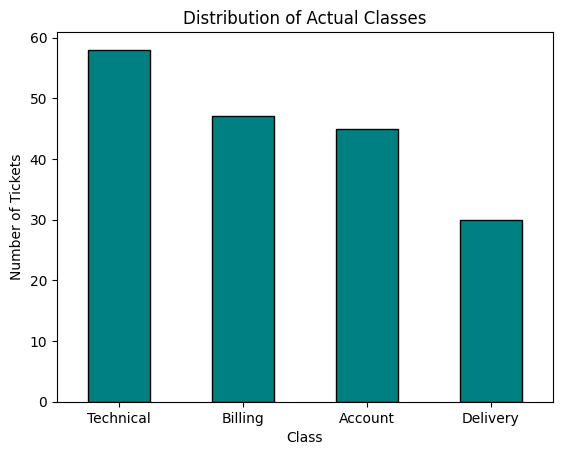

In [8]:
print(df["Actual"].value_counts())

df["Actual"].value_counts().plot(kind="bar", color="teal", edgecolor="black")
plt.title("Distribution of Actual Classes")
plt.xlabel("Class")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.show()

## Task 3 — Separate Actual and Predicted Labels

In [9]:
y_true = df["Actual"]
y_pred = df["Predicted"]

# Fixed class order used everywhere below
labels = sorted(y_true.unique())
print("Class order:", labels)

Class order: ['Account', 'Billing', 'Delivery', 'Technical']


## Task 4 — Generate the Confusion Matrix
Rows = **actual** class, columns = **predicted** class.

In [10]:
cm = confusion_matrix(y_true, y_pred, labels=labels)

cm_df = pd.DataFrame(cm,
                     index=[f"Actual {c}" for c in labels],
                     columns=[f"Pred {c}" for c in labels])
cm_df

,Pred Account,Pred Billing,Pred Delivery,Pred Technical
Actual Account,31,1,4,9
Actual Billing,3,40,0,4
Actual Delivery,5,1,22,2
Actual Technical,5,5,1,47


In [11]:

print("Correct predictions per class:")
for cls, n in zip(labels, np.diag(cm)):
    print(f"  {cls:<10} {n}")

print("\nMisclassifications (actual -> predicted):")
for i, actual in enumerate(labels):
    for j, pred in enumerate(labels):
        if i != j and cm[i, j] > 0:
            print(f"  {actual:<10} -> {pred:<10} {cm[i, j]}")

Correct predictions per class:
  Account    31
  Billing    40
  Delivery   22
  Technical  47

Misclassifications (actual -> predicted):
  Account    -> Billing    1
  Account    -> Delivery   4
  Account    -> Technical  9
  Billing    -> Account    3
  Billing    -> Technical  4
  Delivery   -> Account    5
  Delivery   -> Billing    1
  Delivery   -> Technical  2
  Technical  -> Account    5
  Technical  -> Billing    5
  Technical  -> Delivery   1


## Task 5 — Visualize the Confusion Matrix

In [12]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels,
            linewidths=0.5, linecolor="white")
plt.title("Confusion Matrix — Support Ticket Classifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 700x550 with 0 Axes>

## Task 6 — Calculate Classification Metrics
`average=None` returns one value per class (no weighted / macro / micro averaging).

In [ ]:
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, labels=labels, average=None)
recall    = recall_score(y_true, y_pred, labels=labels, average=None)
f1        = f1_score(y_true, y_pred, labels=labels, average=None)

print(f"Accuracy: {accuracy:.4f}\n")

metrics_df = pd.DataFrame({
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}, index=labels).round(4)
metrics_df

Accuracy: 0.7778



,Precision,Recall,F1-score
Account,0.7045,0.6889,0.6966
Billing,0.8511,0.8511,0.8511
Delivery,0.8148,0.7333,0.7719
Technical,0.7581,0.8103,0.7833


## Task 7 — Generate Classification Report

In [ ]:
print(classification_report(y_true, y_pred, labels=labels, digits=4))

              precision    recall  f1-score   support

     Account     0.7045    0.6889    0.6966        45
     Billing     0.8511    0.8511    0.8511        47
    Delivery     0.8148    0.7333    0.7719        30
   Technical     0.7581    0.8103    0.7833        58

    accuracy                         0.7778       180
   macro avg     0.7821    0.7709    0.7757       180
weighted avg     0.7784    0.7778    0.7774       180



## Task 8 — Calculate Accuracy Using NumPy
Accuracy = sum of diagonal (correct) / sum of all cells (total).

In [ ]:
manual_accuracy = np.trace(cm) / np.sum(cm)
sklearn_accuracy = accuracy_score(y_true, y_pred)

print(f"Correct predictions : {np.trace(cm)}")
print(f"Total predictions   : {np.sum(cm)}")
print(f"Manual (NumPy)      : {manual_accuracy:.4f}")
print(f"Scikit-learn        : {sklearn_accuracy:.4f}")
print("Match:", np.isclose(manual_accuracy, sklearn_accuracy))

Correct predictions : 140
Total predictions   : 180
Manual (NumPy)      : 0.7778
Scikit-learn        : 0.7778
Match: True


## Task 9 — Interpret the Results

In [ ]:
print("Highest precision:", metrics_df["Precision"].idxmax(), metrics_df["Precision"].max())
print("Highest recall:   ", metrics_df["Recall"].idxmax(), metrics_df["Recall"].max())
print("Highest F1-score: ", metrics_df["F1-score"].idxmax(), metrics_df["F1-score"].max())
print("Lowest F1-score:  ", metrics_df["F1-score"].idxmin(), metrics_df["F1-score"].min())

pairs = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        pairs.append((labels[i], labels[j], cm[i, j], cm[j, i], cm[i, j] + cm[j, i]))
pairs_df = pd.DataFrame(pairs, columns=["Class A", "Class B", "A->B", "B->A", "Total"])
pairs_df.sort_values("Total", ascending=False).reset_index(drop=True)

Highest precision: Billing 0.8511
Highest recall:    Billing 0.8511
Highest F1-score:  Billing 0.8511
Lowest F1-score:   Account 0.6966


,Class A,Class B,A->B,B->A,Total
0,Account,Technical,9,5,14
1,Account,Delivery,4,5,9
2,Billing,Technical,4,5,9
3,Account,Billing,1,3,4
4,Delivery,Technical,2,1,3
5,Billing,Delivery,0,1,1


### Answers

**1. Which class has the highest precision?**
**Billing** (0.851). When the model predicts *Billing*, it is right about 85% of the time (40 of 47 Billing predictions).

**2. Which class has the highest recall?**
**Billing** (0.851). The model correctly finds 40 of the 47 real Billing tickets.

**3. Which class has the highest F1-score?**
**Billing** (0.851). It has the best balance of precision and recall.

**4. Which class is the most difficult for the classifier to identify?**
**Account.** It has the lowest recall (0.689), the lowest precision (0.705) and the lowest F1-score (0.697).
Only 31 of the 45 Account tickets are classified correctly. 9 are sent to Technical, 4 to Delivery and 1 to Billing.

**5. Which classes are most frequently confused with each other?**
**Account and Technical**, with 14 confusions in total: 9 Account tickets were predicted as Technical, and 5 Technical tickets were predicted as Account.
Account → Technical (9) is also the largest single off-diagonal cell. This makes sense because login and profile problems often look like technical errors.
The next most confused pairs are Account–Delivery (4 + 5 = 9) and Billing–Technical (4 + 5 = 9).

**6. What does the confusion matrix reveal that a single accuracy value cannot?**
Overall accuracy is 77.8% (140 of 180 correct), but that one number hides several things:
- **Per-class performance differs a lot.** Billing reaches 85%, but Account is only 69%. Accuracy alone suggests every class performs about the same.
- **The type of error.** It shows *which* class each mistake goes to. For example, Account is mostly mistaken for Technical. This tells us where to improve the model, such as with better features to separate login/account issues from technical issues.
- **Direction of the errors.** It separates false positives (column errors, which lower precision) from false negatives (row errors, which lower recall). Technical, for example, has higher recall (0.81) than precision (0.76), because the model over-predicts Technical.
- **Class imbalance.** Technical has 58 tickets and Delivery only 30. A strong result on a large class can hide a weak one on a smaller class.